**1. Installer les bibliothèques**

In [1]:
!pip install ultralytics roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 31.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 65.2 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [ultralytics]


verifier

In [2]:
import ultralytics
import torch

print("Ultralytics:", ultralytics.__version__)
print("GPU disponible :", torch.cuda.is_available())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.208
GPU disponible : True


**2. Télécharger le dataset Roboflow**

In [3]:
from roboflow import Roboflow
rf = Roboflow(api_key="1NkEXFRPMUstUy8Y6BSL")
project = rf.workspace("trainings-workspace-060gs").project("test-fn88j-kwbvl-tyyri")
version = project.version(1)
dataset = version.download("yolov11")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to test-1 in yolov11:: 100%|██████████| 13534/13534 [00:09<00:00, 1424.05it/s]


veridier

In [4]:

# vérifier les images

# Vérifier le nombre d'images dans chaque dossier

import os

for folder in ["train", "valid", "test"]:

    image_path = os.path.join(
        dataset.location, folder, "images"
    )

    images = os.listdir(image_path)

    print(folder, ":", len(images), "images")

train : 4772 images
valid : 1347 images
test : 646 images


**3.connecter ave drive**

In [5]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


**4.Creer le fichier de sauvgarde**

In [6]:
import os

# Créer le dossier de sauvegarde temporaire
project_dir = "/content/drive/MyDrive/IotProject/IotProject"

os.makedirs(project_dir, exist_ok=True)

print("Dossier créé :", project_dir)

Dossier créé : /content/drive/MyDrive/IotProject/IotProject


verifier

In [7]:
import os

print("Dossier existe :", os.path.exists("/content/drive/MyDrive/IotProject/IotProject"))

if os.path.exists("/content/drive/MyDrive/IotProject/IotProject"):
    print(os.listdir("/content/drive/MyDrive/IotProject/IotProject"))

Dossier existe : True
[]


**5.importer le fichier weights.pt depuit github release**

c'est le resultat de 1er entrainement sur roboflow

In [8]:


import os
import requests
from ultralytics import YOLO

# URL publique de la Release
MODEL_URL = (
    "https://github.com/BenWhidaAchwek/Detection_Monnaie_Tunisienne/"
    "releases/download/v0.0.1/weights.pt"
)
# Définir le dossier de destination
MODEL_DIR = "/content/drive/MyDrive/IotProject/models"
# Créer automatiquement le dossier s'il n'existe pas
os.makedirs(MODEL_DIR, exist_ok=True)
# Destination du modèle dans Colab
MODEL_PATH = "/content/drive/MyDrive/IotProject/models/weights.pt"

# Télécharger le fichier
print("Téléchargement du modèle depuis GitHub...")
response = requests.get(MODEL_URL, timeout=120)
response.raise_for_status()

# Enregistrer le modèle
with open(MODEL_PATH, "wb") as file:
    file.write(response.content)

# Charger le modèle avec Ultralytics
model = YOLO(MODEL_PATH)

# Vérifier les classes
print("Modèle chargé avec succès !")
print("Nombre de classes :", len(model.names))
print("Classes :", model.names)


Téléchargement du modèle depuis GitHub...
Modèle chargé avec succès !
Nombre de classes : 11
Classes : {0: 'billet_10_dinars', 1: 'billet_20_dinars', 2: 'billet_50_dinars', 3: 'billet_5_dinars', 4: 'piece_100_millimes', 5: 'piece_1_dinars', 6: 'piece_200_millimes', 7: 'piece_2_dinars', 8: 'piece_500_millimes', 9: 'piece_50_millimes', 10: 'piece_5_dinars'}


définir les chemins nécessaires

In [9]:



import os

# Chemin du fichier data.yaml du dataset Roboflow
DATA_YAML = os.path.join(dataset.location, "data.yaml")

# Dossier pour sauvegarder les résultats
RESULTS_DIR = "/content/drive/MyDrive/IotProject/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Vérifier les chemins
print("DATA_YAML :", DATA_YAML)
print("Fichier YAML existe :", os.path.isfile(DATA_YAML))

print("RESULTS_DIR :", RESULTS_DIR)
print("Dossier résultats existe :", os.path.isdir(RESULTS_DIR))


DATA_YAML : /content/test-1/data.yaml
Fichier YAML existe : True
RESULTS_DIR : /content/drive/MyDrive/IotProject/results
Dossier résultats existe : True


**6. Évaluer le modèle Roboflow (avant le fine-tuning)**

In [10]:
from ultralytics import YOLO

# Évaluer sur le jeu de validation
results1 = model.val(
    data=DATA_YAML,
    split="val",
    imgsz=640,
    batch=4,
    plots=True,
    project=RESULTS_DIR,
    name="roboflow_training"
)

# Afficher les principales métriques

print("mAP50 :", results1.box.map50)
print("mAP50-95 :", results1.box.map)
print("Precision :",results1.box.mp)
print("Recall :", results1.box.mr)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 101 layers, 9,417,057 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1141.8±714.4 MB/s, size: 1076.1 KB)
val: Scanning /content/test-1/valid/labels... 1347 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1347/1347 1.9Kit/s 0.7s
val: New cache created: /content/test-1/valid/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 1, len(boxes) = 2210. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 337/337 10.0it/s 33.7s
                   all       1347       2210      0.901      0.841      0.912      0.769
      billet_10_dinars        282        358      0.939      0.866   

**7. Fine-tuning (2e entraînement)**

In [12]:


from ultralytics import YOLO

# Charger le modèle initial entraîné sur Roboflow
model = YOLO(MODEL_PATH)

# Continuer l'apprentissage à partir de ses poids
train_results = model.train(

    # Dataset Roboflow
    data=DATA_YAML,

    # Paramètres d'entraînement
    epochs=100,
    imgsz=960,
    batch=4,
    device=0,
    patience=15,

    # Optimisation
    optimizer="AdamW",
    lr0=0.0005,
    cos_lr=True,

    # Augmentation des données
    # couleurs et luminosité
    hsv_h=0.015, hsv_s=0.4, hsv_v=0.3,

    # rotation, déplacement, échelle
    degrees=5,translate=0.1,scale=0.3,

    # pas de retournement
    fliplr=0.0,  flipud=0.0,


    # Stabilisation
    close_mosaic=10,
    workers=2,
    seed=42,
    deterministic=True,

    # Sauvegarde
    save=True,
    save_period=10,
    plots=True,

    # Organisation des résultats
    project=RESULTS_DIR,
    name="finetune_yolo11s",
    exist_ok=True
)

print("\nFine-Tuning terminé !")


Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/test-1/data.yaml, degrees=5, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/IotProject/models/weights.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=finetune_yolo11s, nbs=6

**8. Vérifier la sauvegarde et faire une copie du meilleur modèle**

In [15]:
import shutil

BEST = f"{RESULTS_DIR}/finetune_yolo11s/weights/best.pt"
COPIE = "/content/drive/MyDrive/IotProject/best_finetune_yolo11s.pt"

print("best.pt existe :", os.path.exists(BEST))

shutil.copy(BEST, COPIE)

m = YOLO(COPIE)
print("Copie sur Drive ✅ |", round(os.path.getsize(COPIE) / 1e6, 1), "Mo | classes :", len(m.names))

best.pt existe : True
Copie sur Drive ✅ | 19.2 Mo | classes : 11


In [16]:
from google.colab import files

files.download(COPIE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**9.Évaluer le modèle fine-tuné (validation et test)**

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,417,057 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2180.4±1420.7 MB/s, size: 234.1 KB)
val: Scanning /content/test-1/valid/labels.cache... 1347 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1347/1347 269.0Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 1, len(boxes) = 2210. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 337/337 6.7it/s 50.6s
                   all       1347       2210      0.914      0.866      0.925      0.763
      billet_10_dinars        282        358      0.952      0.887      0.948      0.756
      billet_20_dinars        22

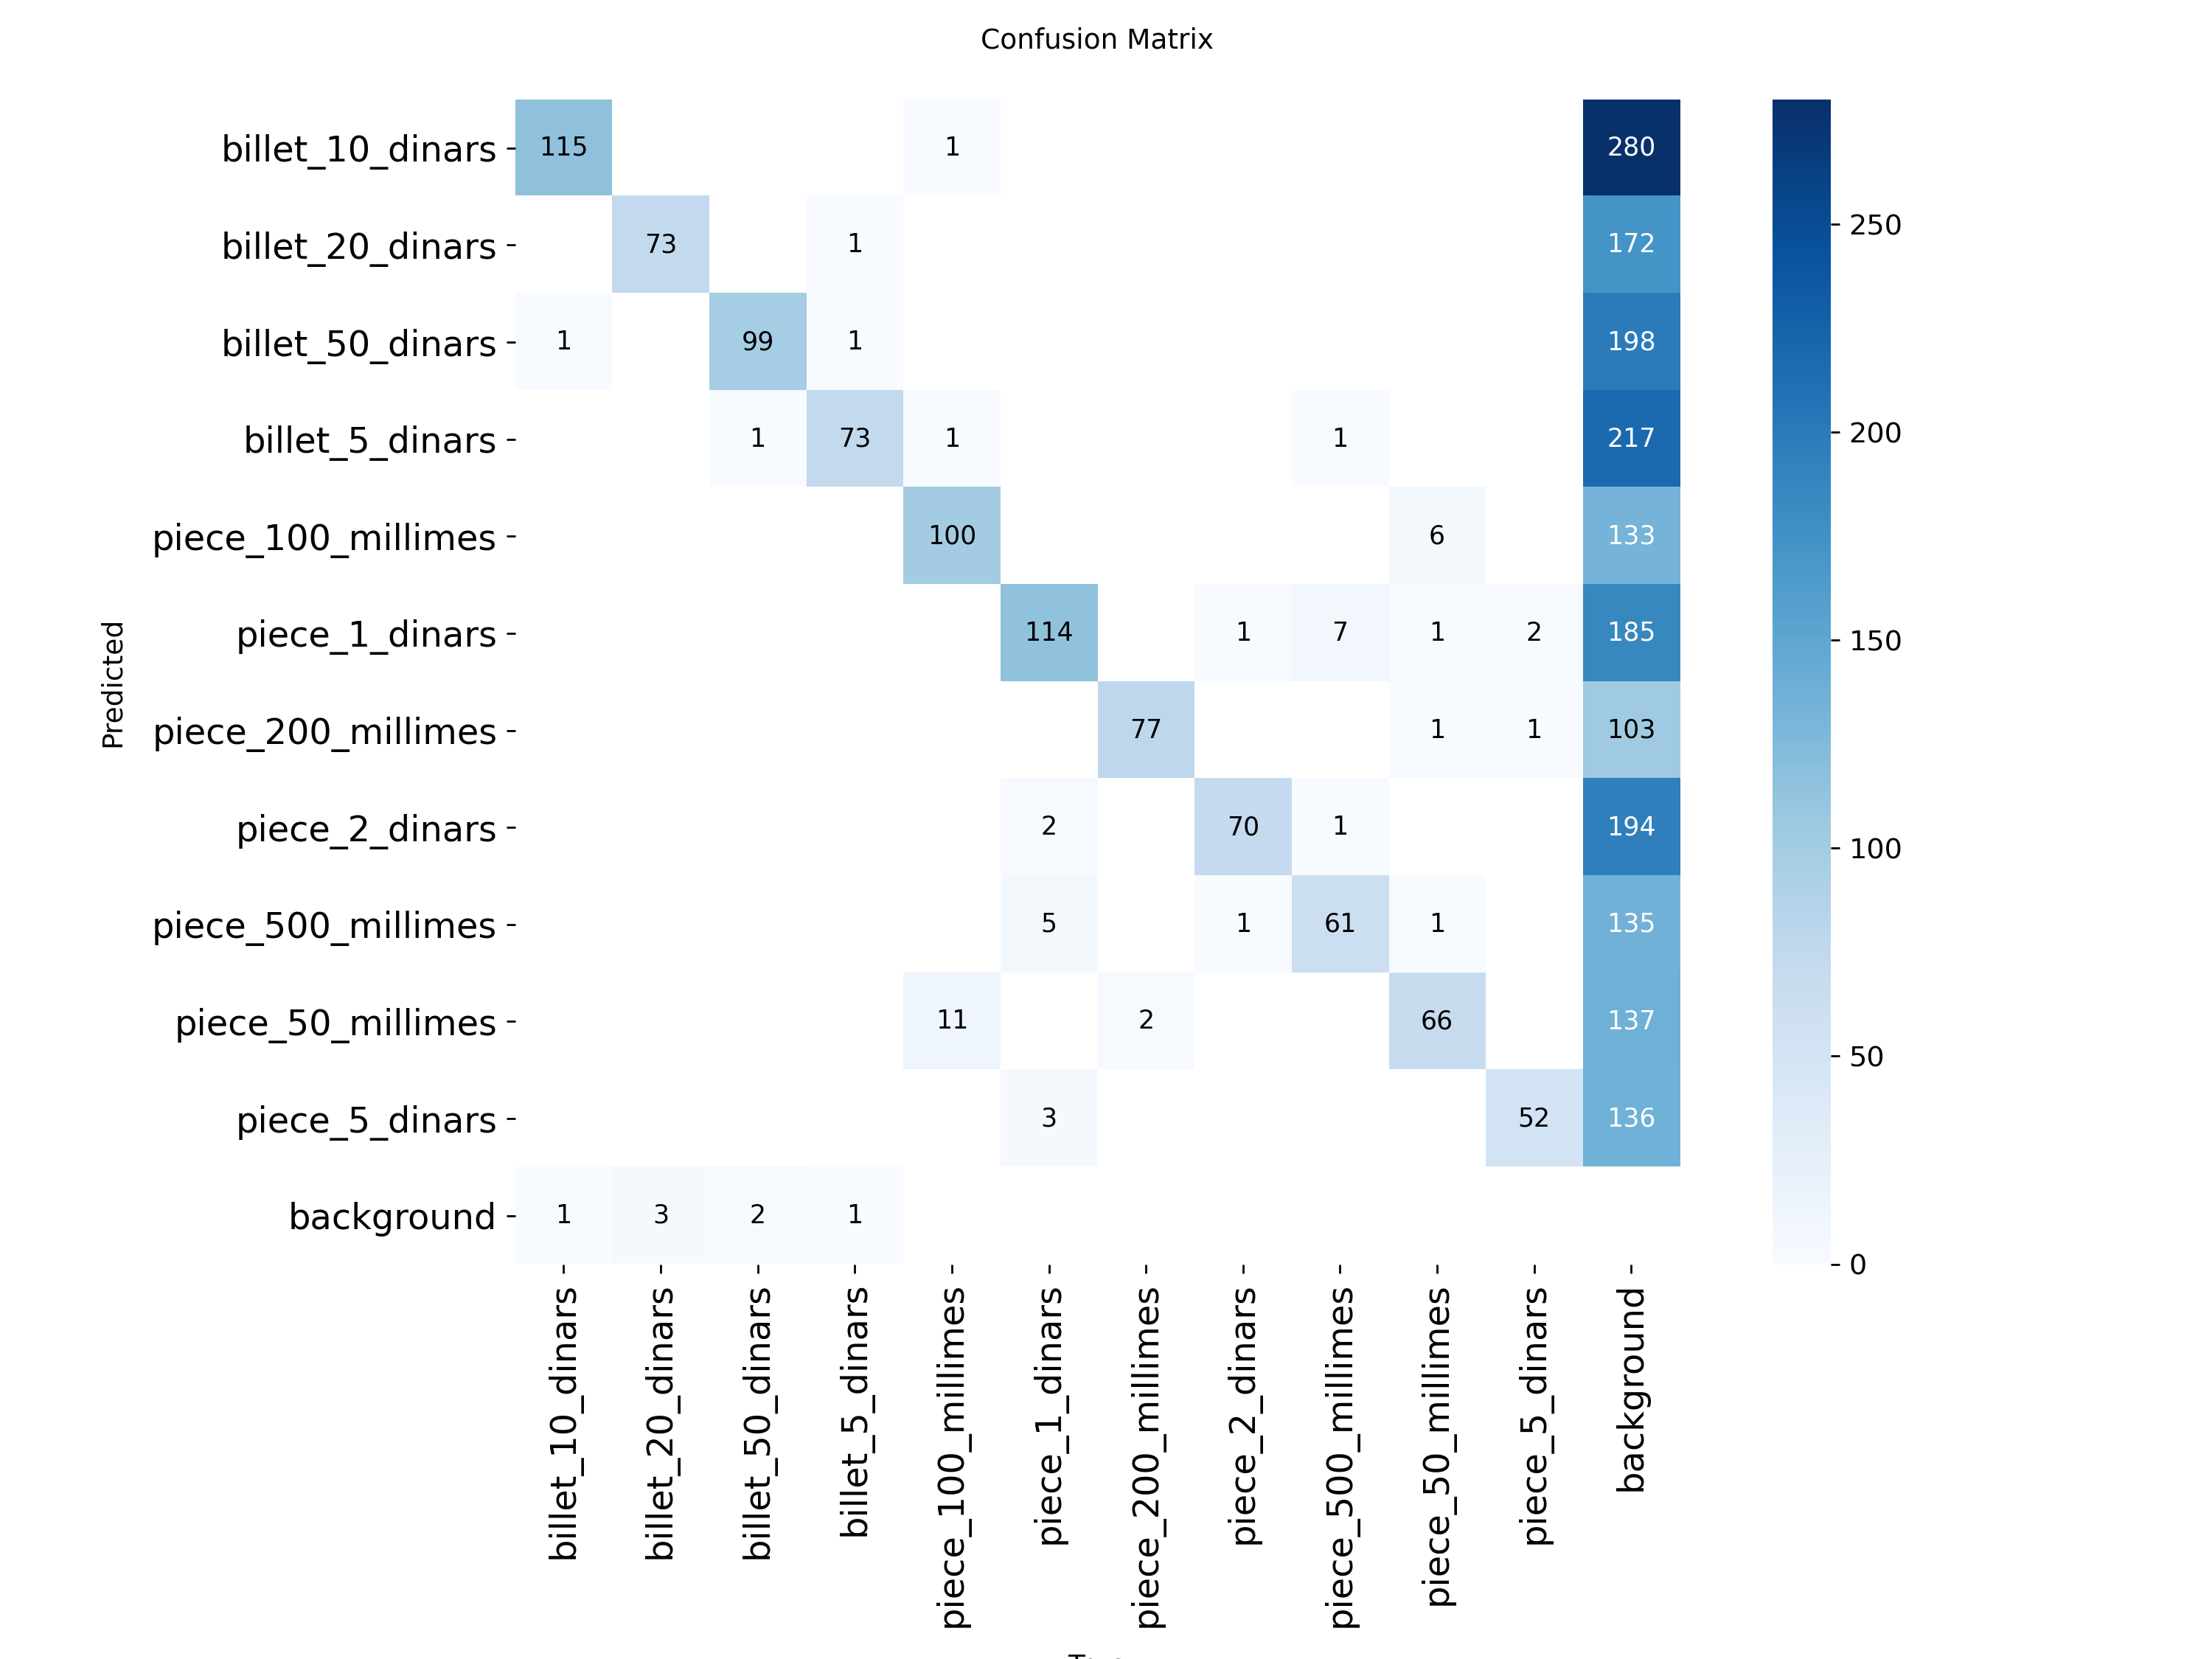

In [17]:
from IPython.display import Image, display

model = YOLO(COPIE)

for split in ["val", "test"]:
    res = model.val(
        data=DATA_YAML,
        split=split,
        imgsz=960,
        batch=4,
        project=RESULTS_DIR,
        name=f"finetune_{split}",
        exist_ok=True,
    )
    print(f"\n===== Résultats ({split}) =====")
    print("mAP50     :", round(res.box.map50, 3))
    print("mAP50-95  :", round(res.box.map, 3))
    print("Precision :", round(res.box.mp, 3))
    print("Recall    :", round(res.box.mr, 3))

# Matrice de confusion (jeu de test)
display(Image(f"{RESULTS_DIR}/finetune_test/confusion_matrix.png", width=700))

**10 Tester sur des images **

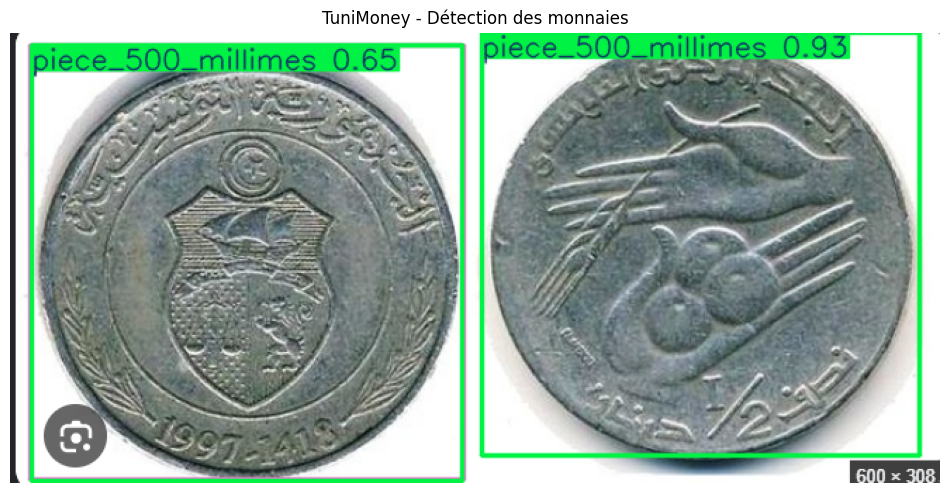

In [22]:

import matplotlib.pyplot as plt
import requests
from PIL import Image
from io import BytesIO

# Image de test sur GitHub
IMAGE_URL = "https://raw.githubusercontent.com/BenWhidaAchwek/Detection_Monnaie_Tunisienne/main/test_image/image1.png"

# Télécharger l'image
response = requests.get(IMAGE_URL)
response.raise_for_status()

# Vérifier et ouvrir l'image
image = Image.open(BytesIO(response.content)).convert("RGB")

# Prédiction YOLO
results = model.predict(
    source=image,
    conf=0.25,
    imgsz=640,
    verbose=False
)

# Afficher l'image annotée
annotated_image = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image[:, :, ::-1])
plt.title("TuniMoney - Détection des monnaies")
plt.axis("off")
plt.show()


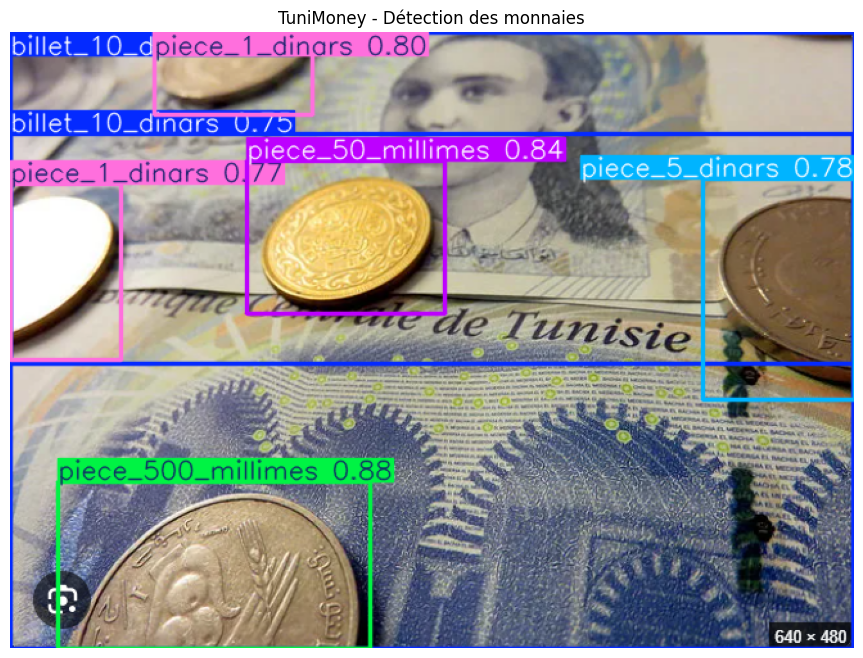

In [23]:

import matplotlib.pyplot as plt
import requests
from PIL import Image
from io import BytesIO

# Image de test sur GitHub
IMAGE_URL = "https://raw.githubusercontent.com/BenWhidaAchwek/Detection_Monnaie_Tunisienne/main/test_image/image3.png"

# Télécharger l'image
response = requests.get(IMAGE_URL)
response.raise_for_status()

# Vérifier et ouvrir l'image
image = Image.open(BytesIO(response.content)).convert("RGB")

# Prédiction YOLO
results = model.predict(
    source=image,
    conf=0.25,
    imgsz=640,
    verbose=False
)

# Afficher l'image annotée
annotated_image = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image[:, :, ::-1])
plt.title("TuniMoney - Détection des monnaies")
plt.axis("off")
plt.show()


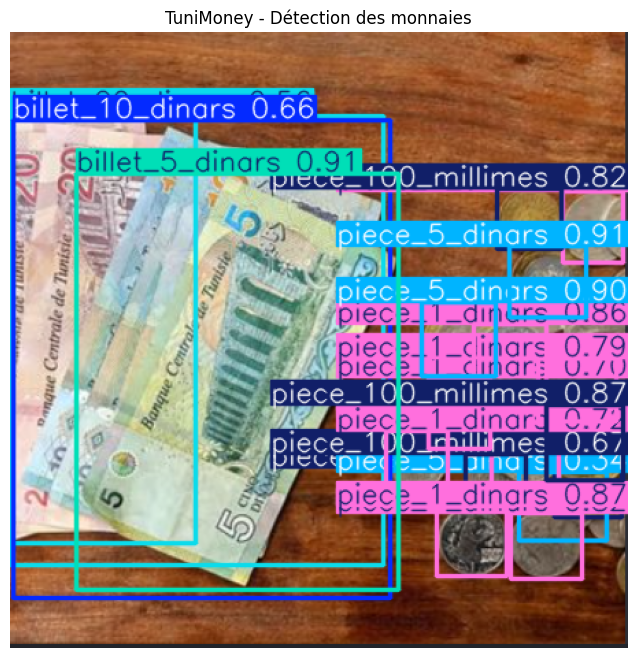


RÉSULTATS 
piece_5_dinars : 3
billet_5_dinars : 1
piece_100_millimes : 4
piece_1_dinars : 8
billet_10_dinars : 1
billet_20_dinars : 2
-----------------------------------------
Nombre total d'objets détectés : 19


In [25]:

import matplotlib.pyplot as plt
import requests
from PIL import Image
from io import BytesIO
from collections import Counter

# Image de test sur GitHub
IMAGE_URL = "https://raw.githubusercontent.com/BenWhidaAchwek/Detection_Monnaie_Tunisienne/main/test_image/image5.png"

# Télécharger l'image
response = requests.get(IMAGE_URL)
response.raise_for_status()

# Vérifier et ouvrir l'image
image = Image.open(BytesIO(response.content)).convert("RGB")

# Prédiction YOLO
results = model.predict(
    source=image,
    conf=0.25,
    imgsz=640,
    verbose=False
)

# Afficher l'image annotée
annotated_image = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image[:, :, ::-1])
plt.title("TuniMoney - Détection des monnaies")
plt.axis("off")
plt.show()


# Afficher le nom et le nombre de chaque classe détectée


classes_detectees = []

for box in results[0].boxes:
    class_id = int(box.cls[0])
    class_name = model.names[class_id]
    classes_detectees.append(class_name)

# Compter les objets par classe
comptage = Counter(classes_detectees)

print("\nRÉSULTATS ")

if comptage:
    for nom_classe, nombre in comptage.items():
        print(f"{nom_classe} : {nombre}")

    print("-----------------------------------------")
    print("Nombre total d'objets détectés :", len(classes_detectees))
else:
    print("Aucune monnaie détectée.")





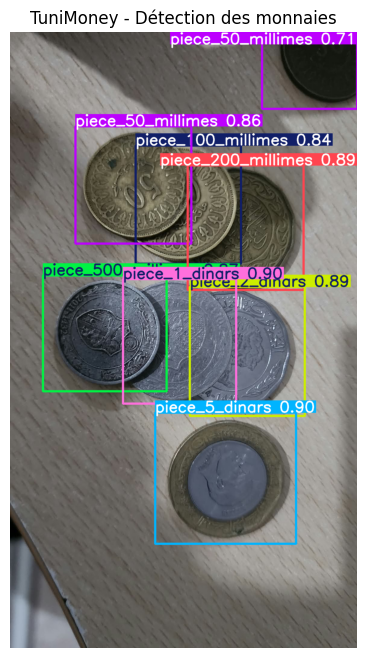


RÉSULTATS 
piece_5_dinars : 1
piece_1_dinars : 1
piece_2_dinars : 1
piece_200_millimes : 1
piece_500_millimes : 1
piece_50_millimes : 2
piece_100_millimes : 1
-----------------------------------------
Nombre total d'objets détectés : 8


In [26]:

import matplotlib.pyplot as plt
import requests
from PIL import Image
from io import BytesIO
from collections import Counter
# Image de test sur GitHub
IMAGE_URL = "https://raw.githubusercontent.com/BenWhidaAchwek/Detection_Monnaie_Tunisienne/main/test_image/image30.jpg"

# Télécharger l'image
response = requests.get(IMAGE_URL)
response.raise_for_status()

# Vérifier et ouvrir l'image
image = Image.open(BytesIO(response.content)).convert("RGB")

# Prédiction YOLO
results = model.predict(
    source=image,
    conf=0.25,
    imgsz=640,
    verbose=False
)

# Afficher l'image annotée
annotated_image = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image[:, :, ::-1])
plt.title("TuniMoney - Détection des monnaies")
plt.axis("off")
plt.show()


# Afficher le nom et le nombre de chaque classe détectée


classes_detectees = []

for box in results[0].boxes:
    class_id = int(box.cls[0])
    class_name = model.names[class_id]
    classes_detectees.append(class_name)

# Compter les objets par classe
comptage = Counter(classes_detectees)

print("\nRÉSULTATS ")

if comptage:
    for nom_classe, nombre in comptage.items():
        print(f"{nom_classe} : {nombre}")

    print("-----------------------------------------")
    print("Nombre total d'objets détectés :", len(classes_detectees))
else:
    print("Aucune monnaie détectée.")




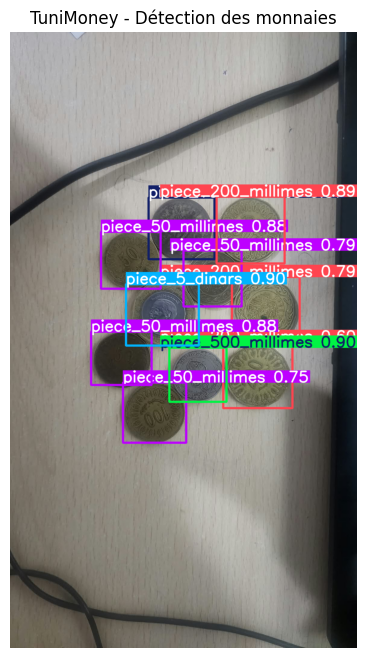


RÉSULTATS 
piece_5_dinars : 1
piece_500_millimes : 1
piece_200_millimes : 3
piece_50_millimes : 4
piece_100_millimes : 1
-----------------------------------------
Nombre total d'objets détectés : 10


In [27]:

import matplotlib.pyplot as plt
import requests
from PIL import Image
from io import BytesIO
from collections import Counter

# Image de test sur GitHub
IMAGE_URL = "https://raw.githubusercontent.com/BenWhidaAchwek/Detection_Monnaie_Tunisienne/main/test_image/image31.jpg"

# Télécharger l'image
response = requests.get(IMAGE_URL)
response.raise_for_status()

# Vérifier et ouvrir l'image
image = Image.open(BytesIO(response.content)).convert("RGB")

# Prédiction YOLO
results = model.predict(
    source=image,
    conf=0.25,
    imgsz=640,
    verbose=False
)

# Afficher l'image annotée
annotated_image = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image[:, :, ::-1])
plt.title("TuniMoney - Détection des monnaies")
plt.axis("off")
plt.show()
# Afficher le nom et le nombre de chaque classe détectée


classes_detectees = []

for box in results[0].boxes:
    class_id = int(box.cls[0])
    class_name = model.names[class_id]
    classes_detectees.append(class_name)

# Compter les objets par classe
comptage = Counter(classes_detectees)

print("\nRÉSULTATS ")

if comptage:
    for nom_classe, nombre in comptage.items():
        print(f"{nom_classe} : {nombre}")

    print("-----------------------------------------")
    print("Nombre total d'objets détectés :", len(classes_detectees))
else:
    print("Aucune monnaie détectée.")





📊 Courbes d'entraînement (results.png)


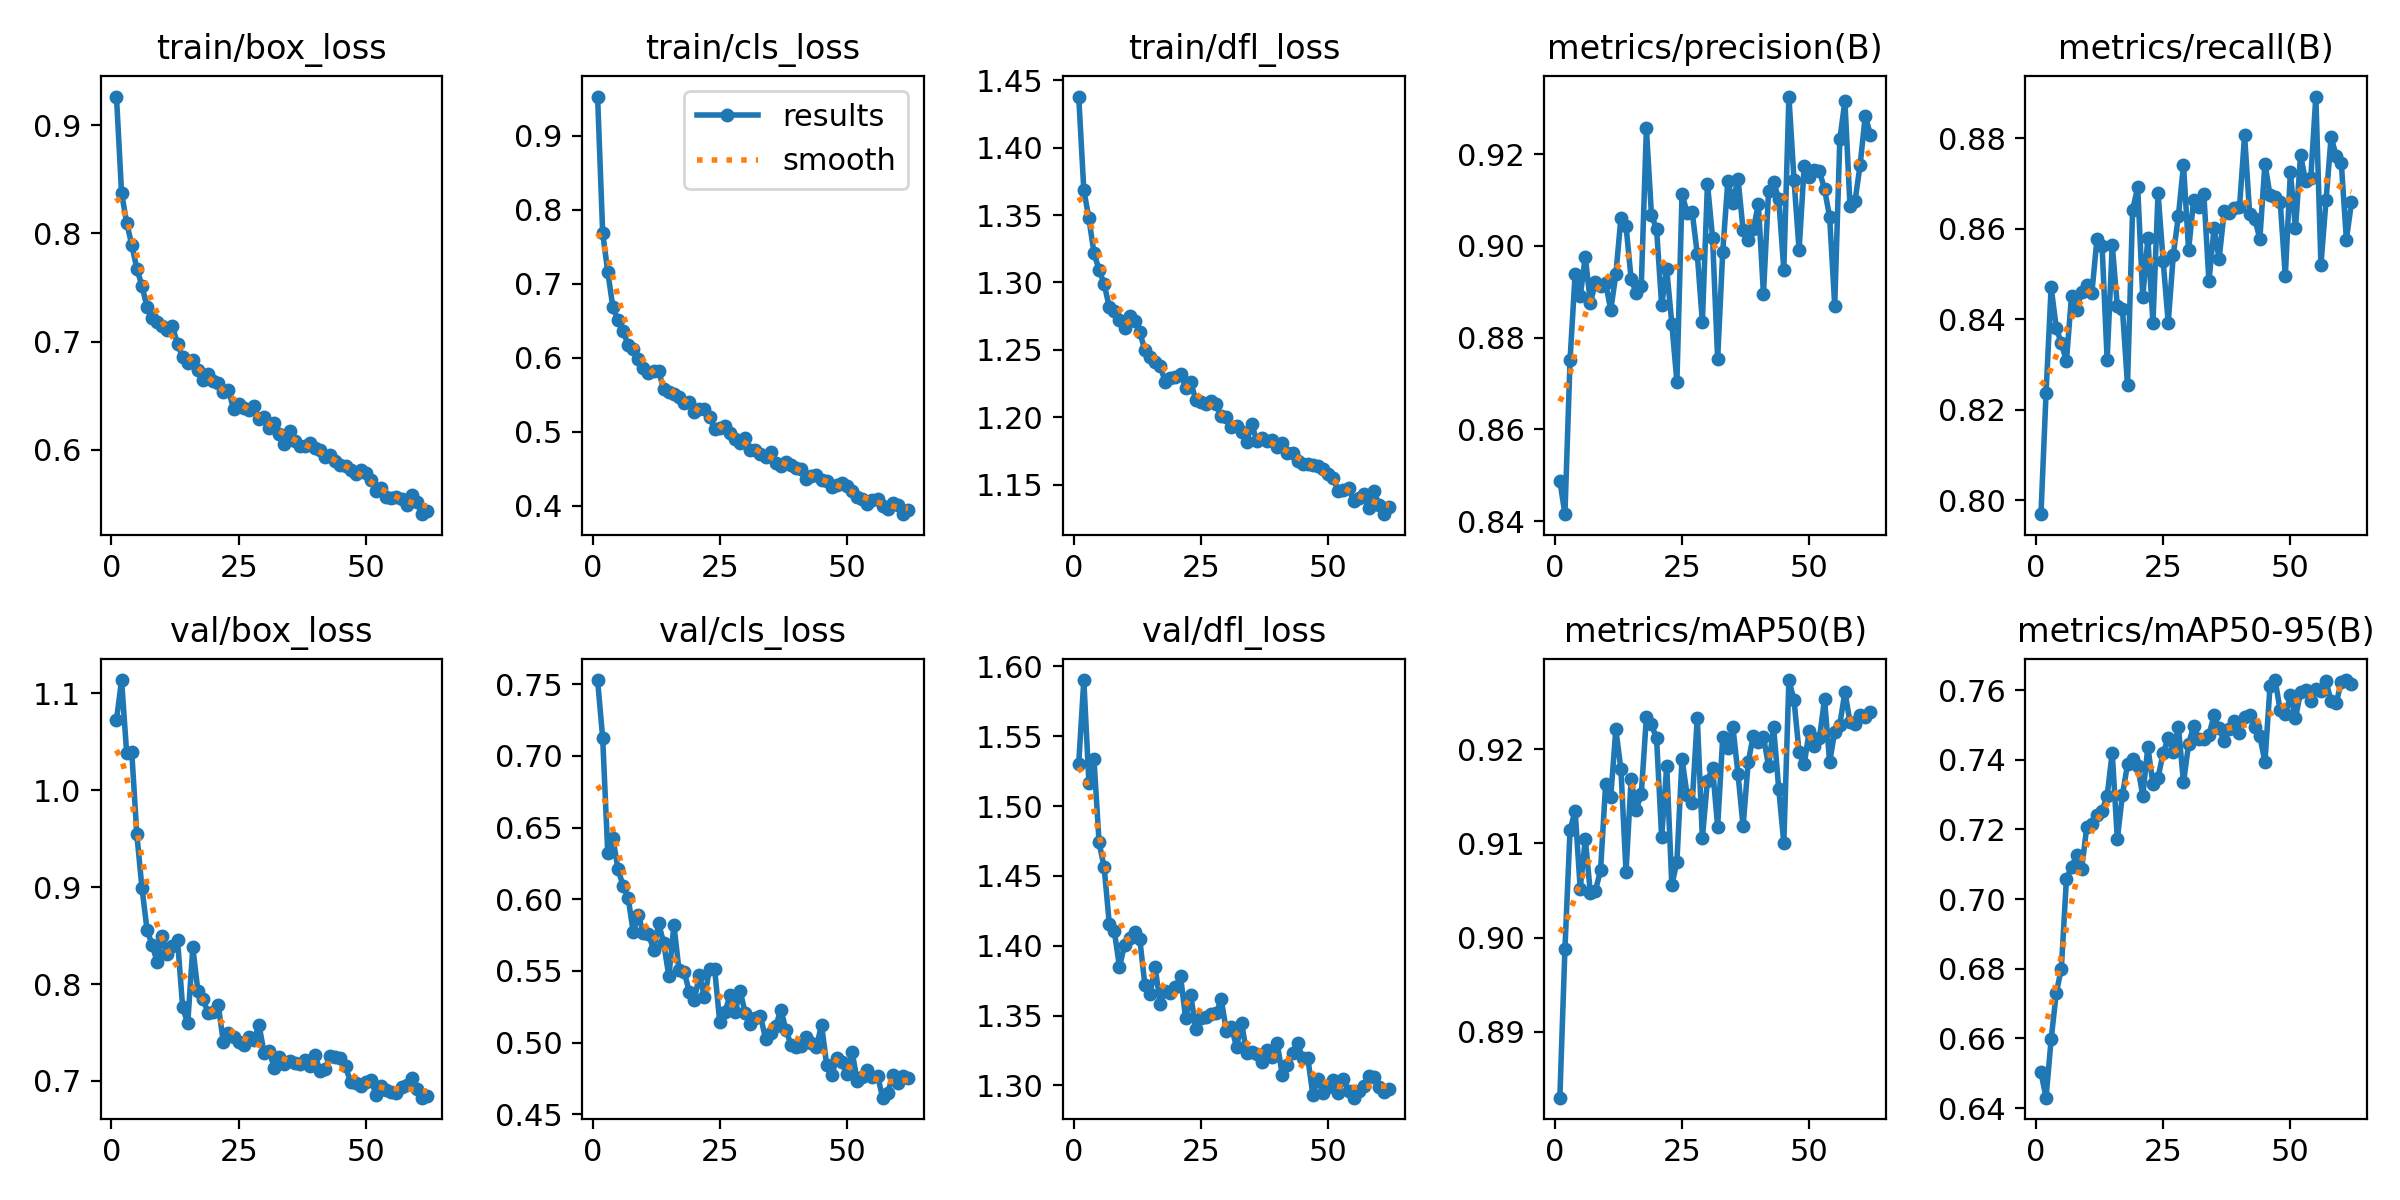


🏆 Meilleure epoch : 46 | mAP50 = 0.927 | mAP50-95 = 0.761


,epoch,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B)
57,58,0.90876,0.88027,0.92290,0.75684
58,59,0.90985,0.87614,0.92270,0.75631
59,60,0.91773,0.87456,0.92361,0.76231
60,61,0.92835,0.85760,0.92342,0.76277
61,62,0.92428,0.86583,0.92394,0.76187


In [29]:
import os
import pandas as pd
from IPython.display import Image as IPImage, display   # alias pour ne pas écraser PIL.Image

# Dossier où YOLO a sauvegardé le fine-tuning (étape 7)
TRAIN_DIR = f"{RESULTS_DIR}/finetune_yolo11s"

def afficher(chemin, titre, largeur=900):
    """Affiche une image générée par YOLO si elle existe."""
    if os.path.exists(chemin):
        print(f"\n📊 {titre}")
        display(IPImage(chemin, width=largeur))
    else:
        print(f"⚠️ Introuvable : {chemin}")

# Courbes loss / précision / rappel / mAP pendant les epochs
afficher(f"{TRAIN_DIR}/results.png", "Courbes d'entraînement (results.png)", 1100)

# Tableau des résultats : meilleure epoch + dernières epochs
df = pd.read_csv(f"{TRAIN_DIR}/results.csv")
df.columns = df.columns.str.strip()                      # enlève les espaces dans les noms
meilleure = df["metrics/mAP50(B)"].idxmax()              # epoch avec le meilleur mAP50
print(f"\n🏆 Meilleure epoch : {int(df.loc[meilleure, 'epoch'])} "
      f"| mAP50 = {df.loc[meilleure, 'metrics/mAP50(B)']:.3f} "
      f"| mAP50-95 = {df.loc[meilleure, 'metrics/mAP50-95(B)']:.3f}")
display(df[["epoch", "metrics/precision(B)", "metrics/recall(B)",
            "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].tail(5))